# Makemore: part 3


In [4]:
import torch
import torch.nn.functional as F 
import matplotlib.pyplot as plt 
import math
%matplotlib inline

In [5]:
# read in all the words 
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [6]:
len(words)

32033

In [7]:
# build the vocab
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [8]:
# build the dataset
block_size = 3

def build_dataset(words):
    X, Y = [], []

    for w in words:
        content = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(content)
            Y.append(ix)
            content = content[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)

    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))


Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%



torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [9]:
# MLP revisited 
n_embd = 10 
n_hidden = 200 

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),       generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
#b1 = torch.randn(n_hidden,  generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),        generator=g) * 0.01
b2 = torch.randn(vocab_size,            generator=g) * 0

# batchNorm parameters:

# bngain = ones, bnbias = zeros — these are the learnable 
# parameters that let the network undo/adjust 
# the normalization if it wants to
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

#bnmean_running = zeros, bnstd_running = ones — these
#  are not learnable parameters (no gradient) — they're 
# running estimates of the batch statistics, updated at
#  each training step (usually via something like
# bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani 
# at bottom
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


12097


1. why b is comment here: we calculate the mean where mean is average value of all so adding the bias after the mean calculated or to linear function xw + b is same so we commented b1 at both "the code block up and down"
- The substitute: Instead of b1, we use bnbias (initialized as zeros) which is added after the normalization step. Since it is applied after normalization, it does not get canceled out, giving backpropagation full control over shifting the normalized distribution

2. why b2 is multiplied to 0:
- At initialization, if we add random values to the output bias b2, some characters will start with much higher starting probabilities than others by pure chance. The network becomes "confidently wrong," resulting in an unnaturally high starting loss (like 27.0 in Karpathy's video)


- b2 is the bias of the final output layer (the layer that produces logits right before the softmax function is applied). It is multiplied by 0 (forcing it to be all zeros) to prevent the model from being "confidently wrong" at the very beginning of training



In [10]:
# same optimization as last time
max_steps = 200
bath_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct 
    ix = torch.randint(0, Xtr.shape[0], (bath_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    # linear layer 
    hpreact = embcat @ W1 # + b1 # hidden layer pre-activation
    # BatchNorm layer
    # embcat is 27,6 W1 is 30 * 200
    # -------------------------------------------------------------
    # n8* 200 = 1, 200
    bnmeani = hpreact.mean(0, keepdim=True) # 1, 200 
    bnstdi = hpreact.std(0, keepdim=True) # 1, 200 
    # hpreact = bngain(ones) * (normalized) + bnbias
    #     = 1 * normalized + 0
    #     = normalized
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    #bnmean_running/bnstd_running slowly 
    # average the batch stats over the whole training 
    # run (via EMA, updated under no_grad since they're 
    # not learned by gradients) so you have a stable 
    # dataset-wide mean/std to normalize with at inference
    #  time, when there's no batch to compute stats from.
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # -------------------------------------------------------------
    # non -linearity 
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats 
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/    200: 3.3239


1. why mean becomes 0 
2. why std becomes 1 after computing 

In [11]:
# same optimization as last time
max_steps = 200
bath_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct 
    ix = torch.randint(0, Xtr.shape[0], (bath_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    # linear layer 
    hpreact = embcat @ W1 # + b1 # hidden layer pre-activation
    # BatchNorm layer
    # embcat is 27,6 W1 is 30 * 200
    # -------------------------------------------------------------
    # n8* 200 = 1, 200
    bnmeani = hpreact.mean(0, keepdim=True) # 1, 200 
    bnstdi = hpreact.std(0, keepdim=True) # 1, 200 

    
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    
    with torch.no_grad():
        # It keeps 99.9% of the old history
        # It adds just 0.1% of the current batch's flavor
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # -------------------------------------------------------------
    # non -linearity 
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats 
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/    200: 2.7054


1. what is hidden layer pre-activation: computing wx + b
2. explain in python "with clause" how to use it: it starts and ends automatically 
- __enter__(): This sets up the resource (like opening a file).
- __exit__(): This cleans up the resource (like closing a file).
- makes sure that resources like files, database connections, or network sockets are cleaned up and closed properly after you are done using them, even if your code crashes or runs into an error.

3. what does this do : 


    with torch.no_grad():

    
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

- Ans: It keeps 99.9% of the old history; It adds just 0.1% of the current batch's flavor


### One importent line only:
    
        
        hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    
1. hpreact - bnmeani: This subtracts the average value (mean) of the current batch. It centers the data around 0.
2. / bnstdi: This divides by the standard deviation of the current batch. It squishes or stretches the data so it has a standard spread (variance of 1).
3. bngain * ... + bnbias: The network learns these two parameters (bngain and bnbias) during training. They allow the network to shift and scale the data to whatever range works best for learning.( this is for next class backprop)
![alt text](<Screenshot 2026-09-09 at 5.22.35 PM.png>)

![alt text](<Screenshot 2026-09-09 at 5.22.52 PM.png>)

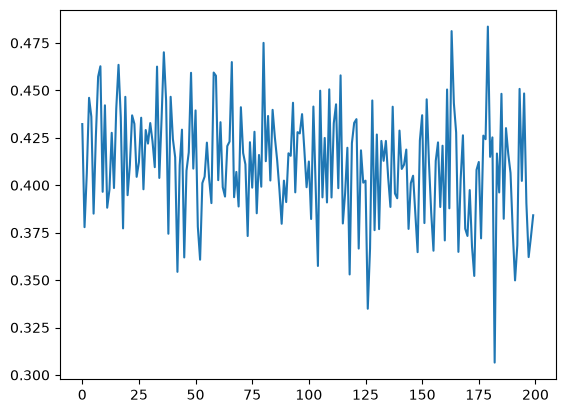

In [12]:
plt.plot(lossi)

In [13]:
# calibrate the batch norm at the end of training 

with torch.no_grad():
    # pass the training set through 
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 # + b1
    # measure the mean/std over the entire training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)


In [14]:
@torch.no_grad() 
def split_loss(split):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        "test": (Xte, Yte),
    }[split]

    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 
    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2 
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.5582656860351562
val 2.553095817565918


## Summary + pytorchifing 

In [16]:
# let's train a deeper network 
# The classes we create here are the same API as nn.Module in PyTorch

class Linear:

    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None


    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps 
        self.momentum = momentum
        self.training = True
        # parameters (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        #buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) /torch.sqrt(xvar + self.eps) # normalize to unit variance
        self.out = self.gamma * xhat + self.beta
        # update the buffers 
        if self.training:

            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

n_embd = 10 
n_hidden = 100
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),       generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size), 
]

with torch.no_grad():
    # last layer: make less confident
    layers[-1].gamma *= 0.1
    # layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 1.0 # 5/3


parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True
    



47024


1. what is eps
2. what does dim mean; torch.zeros(dim) => 
3. what does buffers mean

In [ ]:
# same optimization as last time 
max_steps = 200
bath_size = 32
lossi = []
ud = []

for i in range(max_steps):

    # minibatch construct 
    ix = torch.randint(0, Xtr.shape[0], (bath_size, ), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    

1. what is ud =>